# Liver: ECM composition and organisation in naive and infected mouse liver (Figure 3)

Reproduce Figure 3, panels a to i, of the Mantpy paper from the raw images: 24 imaging mass cytometry ROIs from
eight mice (naive or *Schistosoma mansoni*-infected; *Sox9* knockout or wild type), six ECM markers.

The notebook follows the paper's order:

1. normalise the images and divide them into 10 x 10-pixel ECM patches;
2. train a small CNN on the patches and group them into six ECM clusters (ECM 0 to 5);
3. describe the clusters: composition (a), marker profiles (b), co-occurrence on the patch graph (c),
   images and cluster maps (d, e), and connected regions of the infection-associated cluster (i);
4. predict infection in each held-out mouse with a graph neural network (g) and locate the patches that
   drive the prediction with integrated gradients (f, h).

How this run relates to the paper:

- **The CNN is retrained here from scratch**, starting from random weights, with the paper's final settings.
  No stored cluster labels are used and no settings are searched.
- **One training seed (seed 0)** is used for the CNN and for the classifiers. The paper averages the classifier
  over five seeds; the five-seed ensemble, the permutation test and the tuned classifiers are not run here.
- Results are therefore **close to, but not identical with, the paper**. Each panel is drawn in the paper's
  style and is followed by a small table with this run's values next to the paper's
  (`source_data/fig3.xlsx`).

**Runtime about 6 minutes** with a CUDA GPU (measured on an RTX 3080 Ti), excluding
installation and the first dataset download. A run on a CPU alone has not been timed and will be much slower; the CNN training takes
most of the time. The longer steps print their own time.

Requirements: `mantpy[patch,gnn]` 1.2.0 or newer, `openpyxl` to read the source-data workbook, and this repository's `figures/` and
`source_data/` folders (the notebook reads them by relative path).

In [ ]:
# Google Colab only: fetch this repository and install the packages. Skipped on your own computer.
import os, subprocess, sys
if "google.colab" in sys.modules:
    if not os.path.exists("mantpy_reproducibility"):
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/moeghaf/mantpy_reproducibility"], check=True)
    os.chdir("mantpy_reproducibility/notebooks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "liver_requirements.txt"], check=True)

In [1]:
import logging
import sys
import time
import warnings
from pathlib import Path

# Keep the output short: no deprecation notes and no start-up messages from PyTorch Lightning.
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
warnings.filterwarnings("ignore", module=r"(pytorch_lightning|lightning|lightning_fabric|torch)")
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter
from sklearn.metrics import roc_auc_score

import mantpy as mt

sys.path.insert(0, str(Path("../figures").resolve()))
from _paper import fig3            # the paper's drawing code for Figure 3 (colours, sizes, panel functions)

SEED = 0
CNN_EPOCHS = 200                   # contrastive training of the patch encoder
GNN_EPOCHS = 120                   # training of each GraphSAGE classifier
K = 6                              # number of ECM clusters
PATCH = 10                         # patch side, pixels
GRID = 1000 // PATCH               # patches per image side (every ROI is 1,000 x 1,000 pixels)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SOURCE_DATA = Path("../source_data/fig3.xlsx")
PAPER_CLUSTER = 5                  # the infection-associated cluster in the paper; used only to read the paper's tables

# Full float32 precision on the GPU, as in the paper's runs.
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False

_ = mt.nn.PatchEncoder             # loads PyTorch Lightning now, so that its messages can be switched off
for name in ("pytorch_lightning", "lightning.pytorch", "lightning_fabric", "lightning.fabric"):
    logging.getLogger(name).setLevel(logging.ERROR)

paper = pd.read_excel(SOURCE_DATA, sheet_name=None)    # the paper's values: one table per sheet
tables = {}                                            # this run's tables, named as the drawing code expects

print("Mantpy", mt.__version__, "| device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")

Mantpy 1.2.0.dev0 | device: NVIDIA GeForce RTX 3080 Ti


## 1. Load the liver cohort

`mt.datasets.schistosoma_ecm` downloads the public dataset on first use and returns the raw images
(six ECM markers per ROI), the marker panel and one metadata row per ROI. Naive mice have two ROIs each and
infected mice four.

In [2]:
liver = mt.datasets.schistosoma_ecm(progressbar=False, verbose=False)
images = liver.images                                    # {ROI: raw image, array (6, 1000, 1000)}
MARKERS = list(liver.ecm_names)

meta = liver.sample_meta.drop(columns="sample_id").rename(columns={"mouse_id": "mouse"}).astype(str)
meta.index.name = "roi"
meta["group"] = meta["group"].str.replace("_", " ")      # "Infected KO", as written in the figure

assert MARKERS == fig3.MK and list(images) == sorted(images) == list(meta.index)
assert all(image.shape == (len(MARKERS), 1000, 1000) for image in images.values())
assert [group.replace("_", " ") for group in liver.group_order] == fig3.GROUPS

print(f"{len(images)} ROIs, {meta.mouse.nunique()} mice | markers: " + ", ".join(MARKERS))
meta.groupby("mouse").agg(group=("group", "first"), ROIs=("group", "size"))

24 ROIs, 8 mice | markers: Fibronectin, Pan-laminin, CollagenIV, VersicanV0V1, CollagenI, HeparanSulfate


,group,ROIs
mouse,,
mouse_01,Infected KO,4
mouse_02,Infected KO,4
mouse_03,Infected WT,4
mouse_04,Infected WT,4
mouse_05,Naive KO,2
mouse_06,Naive KO,2
mouse_07,Naive WT,2
mouse_08,Naive WT,2


## 2. Normalise the images and divide them into patches

`mt.pp.ImageNormalizer` with `method="pooled_arcsinh_percentile"` applies arcsinh (cofactor 1), divides each
marker by its 99.5th percentile pooled over all 24 ROIs, and clips to [0, 1].

`mt.pp.ecm_patches_from_images` then divides every image into non-overlapping 10 x 10-pixel patches and
stores, for each patch, the mean and standard deviation of each marker (12 numbers) in
`uns["ecm_patches"]`. All 10,000 patches of an ROI are kept at this stage (`background_quantile=0`,
`ecm_K=None`); background is removed in the next step.

In [3]:
normaliser = mt.pp.ImageNormalizer(
    method="pooled_arcsinh_percentile", cofactor=1.0, percentile=99.5, channel_names=MARKERS,
).fit(images)
normalised = normaliser.transform_cohort(images)

cohort = mt.pp.ecm_patches_from_images(
    normalised, liver.panel, normalize="none",          # the images are already normalised
    patch_size=PATCH, features=["mean", "std"], ecm_K=None, background_quantile=0.0,
)
print(f"{sum(len(adata.uns['ecm_patches']) for adata in cohort.values()):,} patches in {len(cohort)} ROIs")

240,000 patches in 24 ROIs


## 3. Remove background patches

`mt.pp.cluster_ecm_patches` with `n_clusters=2` standardises the 12 patch features over the cohort and splits
the patches into two groups by K-means. `mt.pp.remove_background_patches` marks the dimmer group as
background (label -1). The remaining patches are the ECM signal patches used from here on.

The paper analysed 107,740 signal patches; a fresh run of this step gives 107,732.

In [4]:
two_groups = mt.pp.cluster_ecm_patches(cohort, n_clusters=2, random_state=0, n_init=10)
removed = mt.pp.remove_background_patches(cohort, two_groups)

n_signal = sum(int((adata.uns["ecm_patches"]["ecm_cluster"] >= 0).sum()) for adata in cohort.values())
print(f"ECM signal patches: {n_signal:,} (paper: {paper['b_profiles'].n_patches.sum():,}) | "
      f"background patches: {removed.background_patches:,}")

ECM signal patches: 108,544 (paper: 107,740) | background patches: 131,456


## 4. Train the patch encoder

The encoder looks at pixels, not at patch summaries: its input is the six-channel 10 x 10-pixel block of each
signal patch. `mt.pp.ecm_patch_tiles` cuts these blocks from the normalised images, in the same row order as
the patch tables.

`mt.nn.PatchEncoder` trains a small CNN without labels (contrastive learning): two randomly altered copies
of the same patch (flips, transposition, intensity changes, noise) should receive similar features, and
different patches different ones (NT-Xent loss, temperature 0.1). The options below select the paper's final
encoder:

- two stride-2 convolution blocks with 32 and 64 channels, batch normalisation and GELU;
- 2 x 2 max pooling, then a linear layer to 96 features;
- 200 epochs, batch size 1,024, AdamW with learning rate 3e-4 and weight decay 1e-4.

`encoder.transform` returns the 96 features of every patch.

In [5]:
tiles = mt.pp.ecm_patch_tiles(cohort, normalised, subset="signal")   # (patches, 6 markers, 10, 10)

started = time.perf_counter()
encoder = mt.nn.PatchEncoder(
    latent_dim=96, temperature=0.1,
    conv_blocks=2, conv_width=32, conv_activation="gelu", pool_size=2, pool_type="max",
)
encoder.fit(
    tiles, max_epochs=CNN_EPOCHS, batch_size=1024, lr=3e-4, weight_decay=1e-4,
    random_state=SEED, accelerator=DEVICE, num_workers=0, drop_last=False, exhaust_sampler=True,
    enable_progress_bar=False, enable_model_summary=False,
)
embedding = encoder.transform(tiles, batch_size=4096, standardize=False)

loss = encoder.history["train_loss"]
print(f"{len(tiles):,} patches, {embedding.shape[1]} features each | {len(loss)} epochs in "
      f"{time.perf_counter() - started:.0f} s | contrastive loss {loss[0]:.3f} -> {loss[-1]:.3f}")

108,544 patches, 96 features each | 200 epochs in 276 s | contrastive loss 5.072 -> 0.283


## 5. Group the patches into six ECM clusters

`mt.pp.cluster_ecm_patches` with `embedding=` standardises the 96 features and runs K-means with K = 6 on the
signal patches. `order_by="size"` numbers the clusters ECM 0 to ECM 5 from the largest to the smallest. The
labels are written to the column `ecm_cluster` of each patch table; background patches keep the label -1.

Because the numbers follow cluster size, two clusters of similar size can swap numbers between runs. The
table under panel b shows which paper cluster each cluster of this run resembles.

In [6]:
clusters = mt.pp.cluster_ecm_patches(
    cohort, n_clusters=K, subset="signal", embedding=embedding, random_state=0, n_init=10, order_by="size",
)
pd.DataFrame({"patches, this run": np.asarray(clusters.component_sizes),
              "patches, paper": paper["b_profiles"].n_patches.to_numpy()},
             index=[f"ECM {k}" for k in range(K)])

,"patches, this run","patches, paper"
ECM 0,32969,32469
ECM 1,23950,23232
ECM 2,21847,21786
ECM 3,11354,11982
ECM 4,10505,10036
ECM 5,7919,8235


## 6. One table of all ECM patches

`mt.tl.ecm_patch_table` stacks the patch tables of the 24 ROIs into one long table: one row per signal patch,
with its position, its cluster, and the name of its node in the patch graph (`node_id`), which later steps
use to attach results to patches.

In [7]:
patches = (
    mt.tl.ecm_patch_table(cohort, sample_meta=meta[["mouse", "group"]], drop_background=True)
    .rename(columns={"sample_id": "roi", "ecm_cluster": "cluster"})
    .astype({"x": int, "y": int, "cluster": int})
)
tables["patches"] = patches
print(f"{len(patches):,} labelled ECM patches")

108,544 labelled ECM patches


## 7. Composition per mouse and the infection-associated cluster

`mt.tl.compute_cluster_composition` counts the patches of each cluster. With `unit_col="mouse"` and
`unit_aggregation="pool_counts"` the patches of a mouse are pooled over its ROIs before fractions are taken,
and group values are the mean of the two mice.

The infection-associated cluster is then chosen by the paper's rule, from these fractions alone
(`composition.contrast`, then `mt.tl.top_enriched_cluster`): among the
clusters that make up at least 1% of the ECM patches in every infected mouse, take the one with the largest
ratio of mean infected to mean naive fraction (pseudocount 0.001). In the paper this is ECM 5. The cluster
number used in the rest of the notebook comes from this rule.

In [8]:
composition = mt.tl.compute_cluster_composition(
    cohort, sample_meta=meta, group_col="group", group_order=fig3.GROUPS,
    cluster_col="ecm_cluster", label_source="patches", drop_background=True, categories=range(K),
    unit_col="mouse", unit_aggregation="pool_counts", return_details=True,
)
per_mouse = composition.per_unit                         # rows: mice; columns: clusters 0 to 5
mouse_group = composition.unit_meta["group"]

contrast = composition.contrast(case=["Infected KO", "Infected WT"], control=["Naive KO", "Naive WT"],
                                pseudocount=1e-3, min_fraction=0.01)
INFECTION_CLUSTER = int(mt.tl.top_enriched_cluster(contrast, log2_col="log2_ratio", sig_col="present"))
INFECTION_COLOUR = fig3.PAL[INFECTION_CLUSTER]

print(f"Infection-associated cluster in this run: ECM {INFECTION_CLUSTER} (paper: ECM {PAPER_CLUSTER})")
contrast.set_index("cluster").rename(index="ECM {}".format).round(3)

Infection-associated cluster in this run: ECM 5 (paper: ECM 5)


,mean_case,mean_control,difference,log2_ratio,min_case_fraction,present,n_case_units,n_control_units
cluster,,,,,,,,
ECM 0,0.288,0.300,-0.012,-0.056,0.166,True,4,4
ECM 1,0.259,0.099,0.160,1.381,0.137,True,4,4
ECM 2,0.140,0.429,-0.289,-1.612,0.040,True,4,4
ECM 3,0.108,0.116,-0.008,-0.101,0.071,True,4,4
ECM 4,0.113,0.057,0.056,0.987,0.070,True,4,4
ECM 5,0.092,0.000,0.092,6.465,0.032,True,4,4


## 8. ECM composition (Figure 3a)

Mean fraction of ECM patches in each cluster, per group. The percentage above the infected bars is the share
of the infection-associated cluster. The paper's function for this panel writes "ECM 5" into the drawing, so
the panel is drawn here with the same colours and sizes for whichever cluster the rule selected.

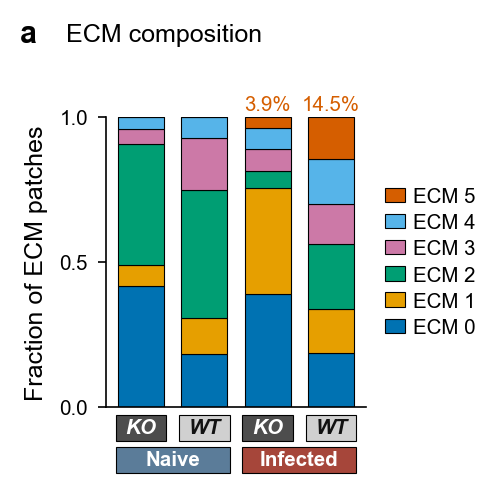

Fraction of ECM patches per group (mean of two mice)


ECM0   ECM1   ECM2   ECM3   ECM4   ECM5
group                                                         
Naive KO    this run  0.418  0.072  0.417  0.052  0.041  0.000
            paper     0.432  0.068  0.406  0.055  0.038  0.000
Naive WT    this run  0.181  0.126  0.442  0.179  0.072  0.000
            paper     0.189  0.109  0.442  0.192  0.067  0.000
Infected KO this run  0.390  0.366  0.056  0.078  0.070  0.039
            paper     0.377  0.366  0.064  0.084  0.068  0.040
Infected WT this run  0.186  0.152  0.223  0.138  0.156  0.145
            paper     0.187  0.144  0.220  0.146  0.150  0.152

Share of the infection-associated cluster in each mouse (this run: ECM 5; paper: ECM 5)


,group,this run,paper
mouse,,,
mouse_01,Infected KO,0.032,0.033
mouse_02,Infected KO,0.045,0.048
mouse_03,Infected WT,0.088,0.095
mouse_04,Infected WT,0.202,0.210
mouse_05,Naive KO,0.000,0.000
mouse_06,Naive KO,0.000,0.000
mouse_07,Naive WT,0.000,0.000
mouse_08,Naive WT,0.000,0.000


In [9]:
tables["groups"] = composition.per_group_mean.rename(columns="ECM{}".format).rename_axis("group")
tables["mouse_fractions"] = per_mouse.rename(columns="ECM{}".format)

canvas = fig3.Canvas(fig3.WF, fig3.HF)
axis = canvas.A(0.45, fig3.y1, 1.3, fig3.h1)
bottom = np.zeros(len(fig3.GROUPS))
for k in range(K):
    fraction = tables["groups"][f"ECM{k}"].to_numpy(float)
    axis.bar(np.arange(len(fig3.GROUPS)), fraction, bottom=bottom, color=fig3.PAL[k], width=0.72,
             edgecolor=fig3.SEP_COL, linewidth=fig3.SEP_LW)
    bottom += fraction
for j, group in enumerate(fig3.GROUPS):
    if group.startswith("Infected"):
        axis.text(j, 1.012, f"{100 * tables['groups'].loc[group, f'ECM{INFECTION_CLUSTER}']:.1f}%",
                  ha="center", va="bottom", fontsize=canvas.ST, color=INFECTION_COLOUR)
axis.set_xlim(-0.55, 3.55); axis.set_ylim(0, 1.0); axis.set_yticks([0, 0.5, 1.0]); axis.set_xticks([])
axis.set_ylabel("Fraction of ECM patches")
canvas.axbands(axis, fig3.BANDS4, fig3.h1)
axis.legend(handles=[Patch(facecolor=fig3.PAL[k], edgecolor=fig3.SEP_COL, linewidth=fig3.SEP_LW, label=f"ECM {k}")
                     for k in range(K - 1, -1, -1)],
            loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=canvas.ST,
            handlelength=1.0, handletextpad=0.4, labelspacing=0.35)
canvas.letter(0.02, fig3.HF - 0.06, "a"); canvas.title(0.25, fig3.HF - 0.08, "ECM composition")
plt.show()

print("Fraction of ECM patches per group (mean of two mice)")
display(pd.concat({"this run": tables["groups"], "paper": paper["a_groups"].set_index("group")[list(tables["groups"])]},
                  names=["", "group"]).swaplevel().loc[fig3.GROUPS].round(3))
print(f"Share of the infection-associated cluster in each mouse "
      f"(this run: ECM {INFECTION_CLUSTER}; paper: ECM {PAPER_CLUSTER})")
display(pd.DataFrame({"group": mouse_group, "this run": tables["mouse_fractions"][f"ECM{INFECTION_CLUSTER}"],
                      "paper": paper["a_mice"].set_index("mouse")[f"ECM{PAPER_CLUSTER}"]}).round(3))

## 9. Marker profiles of the clusters (Figure 3b)

`mt.pl.ecm_centroid_table` returns the mean normalised intensity of each marker in each cluster and its
z-score across the six clusters. The z-scores are drawn with the paper's function.

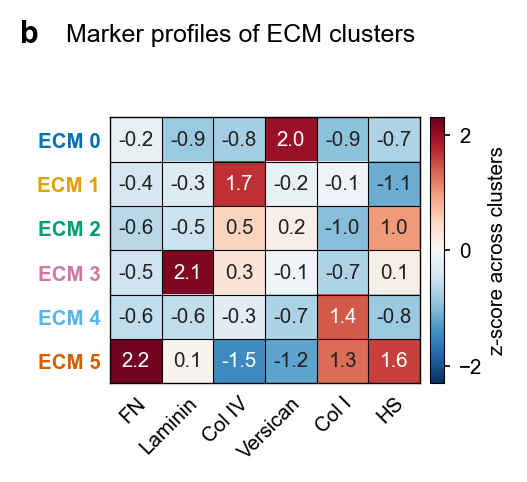

Which paper cluster does each cluster of this run resemble?


,"patches, this run",most similar paper cluster,profile correlation,"patches, that paper cluster"
ECM 0,32969,ECM 0,1.00,32469
ECM 1,23950,ECM 1,1.00,23232
ECM 2,21847,ECM 2,0.99,21786
ECM 3,11354,ECM 3,1.00,11982
ECM 4,10505,ECM 4,1.00,10036
ECM 5,7919,ECM 5,1.00,8235


Marker z-scores (same cluster numbers side by side)


FN  Laminin  Col IV  Versican  Col I    HS
cluster                                                       
0       paper    -0.16    -0.86   -0.79      2.03  -0.96 -0.65
        this run -0.16    -0.86   -0.78      1.99  -0.94 -0.72
1       paper    -0.37    -0.30    1.67     -0.12  -0.10 -1.17
        this run -0.39    -0.29    1.68     -0.15  -0.07 -1.14
2       paper    -0.63    -0.47    0.64      0.02  -0.94  1.01
        this run -0.64    -0.49    0.51      0.15  -0.98  0.98
3       paper    -0.48     2.14    0.22     -0.08  -0.71  0.15
        this run -0.47     2.15    0.31     -0.06  -0.71  0.14
4       paper    -0.57    -0.59   -0.32     -0.68   1.42 -0.89
        this run -0.56    -0.57   -0.26     -0.73   1.41 -0.85
5       paper     2.21     0.08   -1.42     -1.18   1.29  1.54
        this run  2.21     0.06   -1.46     -1.21   1.29  1.58

In [10]:
centroids = mt.pl.ecm_centroid_table(cohort, ecm_names=MARKERS, K_ecm=K)   # one row per cluster and marker
profiles = pd.DataFrame({"cluster": range(K), "n_patches": centroids.groupby("cluster").n_patches.first().to_numpy()})
for value, prefix in (("z_score", "z_mean_"), ("mean_intensity", "raw_mean_")):
    wide = centroids.pivot(index="cluster", columns="marker", values=value)[MARKERS]
    profiles = profiles.join(wide.add_prefix(prefix))
tables["profiles"] = profiles

canvas = fig3.Canvas(fig3.WF, fig3.HF)
fig3.panel_b(canvas, tables)
plt.show()

z_columns = [f"z_mean_{marker}" for marker in MARKERS]
similarity = np.corrcoef(profiles[z_columns].to_numpy(), paper["b_profiles"][z_columns].to_numpy())[:K, K:]
nearest = similarity.argmax(axis=1)                      # the paper cluster with the most similar marker profile
print("Which paper cluster does each cluster of this run resemble?")
display(pd.DataFrame({"patches, this run": profiles.n_patches.to_numpy(),
                      "most similar paper cluster": [f"ECM {k}" for k in nearest],
                      "profile correlation": similarity.max(axis=1).round(2),
                      "patches, that paper cluster": paper["b_profiles"].n_patches.to_numpy()[nearest]},
                     index=[f"ECM {k}" for k in range(K)]))
print("Marker z-scores (same cluster numbers side by side)")
display(pd.concat({"this run": profiles.set_index("cluster")[z_columns],
                   "paper": paper["b_profiles"].set_index("cluster")[z_columns]}, names=["", "cluster"])
        .swaplevel().sort_index().rename(columns=dict(zip(z_columns, fig3.MKL))).round(2))

## 10. Build the patch graphs

`mt.gr.build_ecm_graphs` with `edge_method="delaunay"` joins the centres of **all** patches of an ROI
(signal and background) by Delaunay triangulation and stores the graph in `uns["ecm_graph"]`. Each node
carries its cluster label, so the graphs are built after the labels were written. Later steps use only the
edges between two ECM signal patches.

In [11]:
graph_summary = mt.gr.build_ecm_graphs(cohort, edge_method="delaunay", edge_weight="uniform")
print(f"{graph_summary.n_nodes:,} nodes and {graph_summary.n_edges:,} edges in {len(graph_summary.samples)} ROI graphs")

240,000 nodes and 710,424 edges in 24 ROI graphs


## 11. Co-occurrence of clusters, infected knockout minus wild type (Figure 3c)

`mt.tl.cluster_cooccurrence` counts, for every pair of clusters, the graph edges that join them (observed)
and compares the count with the number expected from cluster abundance alone: log2(observed / expected).
With `unit_col="mouse"` the counts of a mouse are pooled over its ROIs. Positive values mean that the two
clusters are neighbours more often than expected.

The panel shows the mean of the two infected knockout mice minus the mean of the two infected wild-type
mice. The mice are taken from the metadata.

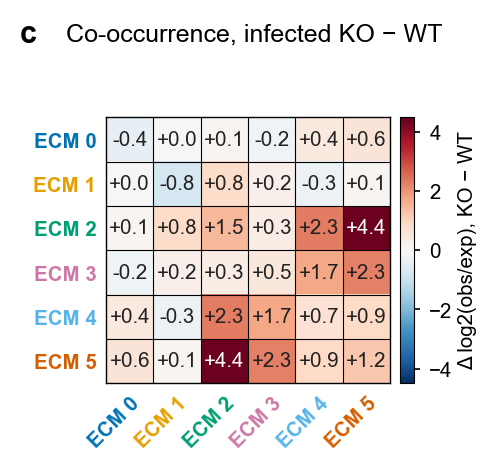

Infected KO: mouse_01, mouse_02 | infected WT: mouse_03, mouse_04
KO minus WT for pairs that include the infection-associated cluster (this run: ECM 5; paper: ECM 5)


,this run,paper
with ECM 0,0.57,0.79
with ECM 1,0.08,0.07
with ECM 2,4.41,4.21
with ECM 3,2.26,2.29
with ECM 4,0.90,0.88
with ECM 5,1.22,1.20


Correlation with the paper over the 21 cluster pairs (same cluster numbers): r = 1.00


In [12]:
cooccurrence = mt.tl.cluster_cooccurrence(
    cohort, n_clusters=K, sample_meta=meta, unit_col="mouse", unit_aggregation="pool_counts",
    return_details=True, missing="nan", eps=1e-9,
)
infected_rois = meta[meta.condition == "Infected"]
KO_MICE = sorted(infected_rois.loc[infected_rois.genotype == "KO", "mouse"].unique())
WT_MICE = sorted(infected_rois.loc[infected_rois.genotype == "WT", "mouse"].unique())
assert len(KO_MICE) == len(WT_MICE) == 2

enrichment = {mouse: cooccurrence.per_unit[mouse].enrichment for mouse in KO_MICE + WT_MICE}
ko_minus_wt = (np.mean([enrichment[mouse] for mouse in KO_MICE], axis=0)
               - np.mean([enrichment[mouse] for mouse in WT_MICE], axis=0))
tables["pairs"] = pd.DataFrame([
    {"cluster_a": a, "cluster_b": b, "ko_minus_wt": ko_minus_wt[a, b],
     **{f"log2_obs_exp_{mouse}": enrichment[mouse][a, b] for mouse in KO_MICE + WT_MICE}}
    for a in range(K) for b in range(a, K)
])

canvas = fig3.Canvas(fig3.WF, fig3.HF)
fig3.panel_c(canvas, tables)
plt.show()

print(f"Infected KO: {', '.join(KO_MICE)} | infected WT: {', '.join(WT_MICE)}")
print(f"KO minus WT for pairs that include the infection-associated cluster "
      f"(this run: ECM {INFECTION_CLUSTER}; paper: ECM {PAPER_CLUSTER})")
paper_matrix = fig3.pair_matrix(paper["c_cooccurrence"], "ko_minus_wt")
display(pd.DataFrame({"this run": ko_minus_wt[INFECTION_CLUSTER], "paper": paper_matrix[PAPER_CLUSTER]},
                     index=[f"with ECM {k}" for k in range(K)]).round(2))
both = np.isfinite(tables["pairs"].ko_minus_wt.to_numpy())
if both.sum() > 2:
    r_pairs = np.corrcoef(tables["pairs"].ko_minus_wt[both], paper["c_cooccurrence"].ko_minus_wt[both])[0, 1]
    print(f"Correlation with the paper over the {both.sum()} cluster pairs (same cluster numbers): r = {r_pairs:.2f}")

## 12. Six-marker images of four ROIs (Figure 3d)

One representative ROI per group (the ROIs shown in the paper). The paper's function `fig3.composite`
normalises a raw image as in step 2 and adds the six markers in their display colours. The normalisation
bounds are the ones fitted in this run; the display threshold and ceiling of each marker are display
settings, read from the source-data workbook.

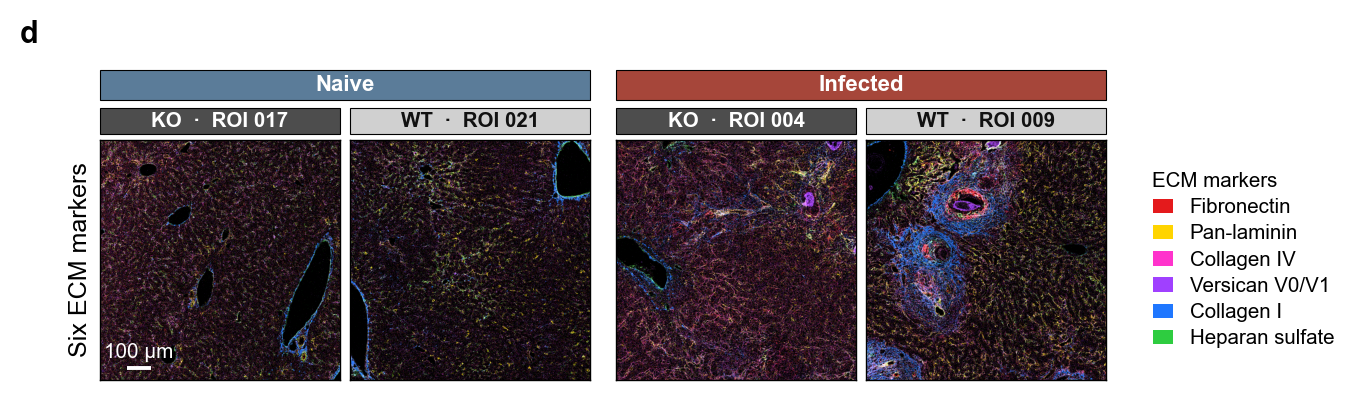

99.5th percentile of each marker after arcsinh (normalisation bound)


,this run,paper
Fibronectin,2.7765,2.7765
Pan-laminin,2.4918,2.4918
CollagenIV,2.3124,2.3124
VersicanV0V1,2.3124,2.3124
CollagenI,3.1798,3.1798
HeparanSulfate,2.4918,2.4918


In [13]:
assert list(paper["d_display"].marker) == MARKERS
display_scale = paper["d_display"].assign(transform_bound_99p5=normaliser.bounds_)
tables["composites"] = {roi: fig3.composite(images[roi], display_scale) for roi in fig3.REP.values()}

canvas = fig3.Canvas(fig3.WF, fig3.HF)
fig3.panel_d(canvas, tables)
plt.show()

print("99.5th percentile of each marker after arcsinh (normalisation bound)")
pd.DataFrame({"this run": normaliser.bounds_, "paper": paper["d_display"].transform_bound_99p5.to_numpy()},
             index=MARKERS).round(4)

## 13. Cluster maps of the same ROIs (Figure 3e)

Each 10 x 10-pixel patch is coloured by its ECM cluster; white patches have no ECM signal.

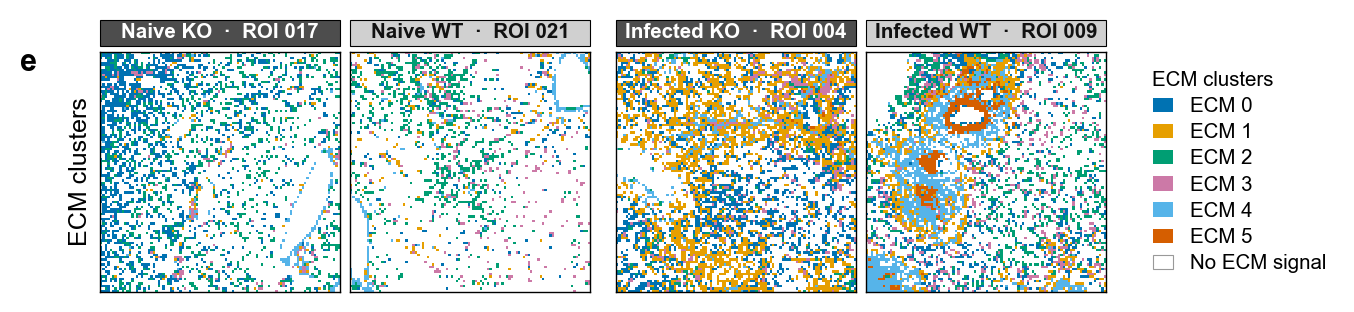

,group,"ECM patches, this run","ECM patches, paper","ECM 5 patches, this run","ECM 5 patches, paper"
roi_017,Naive KO,3155,3123,1,0
roi_021,Naive WT,1843,1821,0,0
roi_004,Infected KO,5429,5389,27,33
roi_009,Infected WT,4650,4617,367,408


In [14]:
canvas = fig3.Canvas(fig3.WF, fig3.HF)
fig3.panel_e(canvas, tables)
for j, group in enumerate(fig3.GROUPS):                  # column headings (on the paper's page they sit above panel d)
    canvas.fband(fig3.colx(j), fig3.colx(j) + fig3.MW, fig3.rowy1 + fig3.MW + 0.03, 0.13, group.split(" ")[1],
                 text=f"{group}  ·  {fig3.REP[group].replace('roi_', 'ROI ')}", fs=canvas.ST)
plt.show()

shown = list(fig3.REP.values())
paper_shown = paper["e_f_patches"]
pd.DataFrame({
    "group": list(fig3.REP),
    "ECM patches, this run": [int((patches.roi == roi).sum()) for roi in shown],
    "ECM patches, paper": [int((paper_shown.roi == roi).sum()) for roi in shown],
    f"ECM {INFECTION_CLUSTER} patches, this run": [int(((patches.roi == roi) & (patches.cluster == INFECTION_CLUSTER)).sum())
                                                 for roi in shown],
    f"ECM {PAPER_CLUSTER} patches, paper": [int(((paper_shown.roi == roi) & (paper_shown.cluster == PAPER_CLUSTER)).sum())
                                            for roi in shown],
}, index=shown)

## 14. Predict infection in each held-out mouse (Figure 3g)

`mt.nn.build_ohe_cluster_graphs` turns each ROI into a graph for learning: the nodes are the ECM signal
patches, the only node feature is the cluster label (one-hot), and the edges are the Delaunay edges between
signal patches. Nothing else about the image is given to the classifier.

`mt.nn.NodeClassifier` trains a two-layer GraphSAGE network (64 hidden units, mean aggregation, dropout 0.2;
120 epochs, Adam, learning rate 5e-3, weight decay 1e-4). Each mouse is held out in turn: the network is
trained on the ROIs of the other seven mice and applied to the ROIs of the held-out mouse.
`loss_reduction="roi"` averages the class-weighted loss within each ROI, so that large ROIs do not dominate.
The probability for a mouse is the mean over its ROIs; 0.5 is the cut-off. The classifier runs on the GPU
when one is available, otherwise on the CPU.

For comparison, `classifier.composition_baseline` fits a logistic regression that is given only the cluster
fractions of each ROI (composition, no graph), with the same held-out mice. Its regularisation strength C for each fold is the value selected in
the paper.

8 held-out mice, 120 epochs each, in 14 s


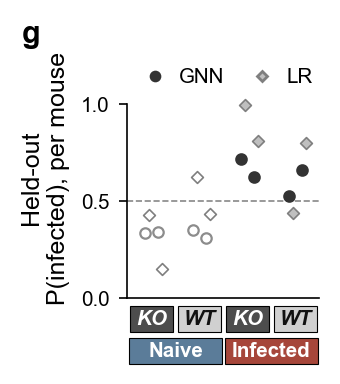

Held-out probability of infection per mouse


,group,"GNN, this run (seed 0)","GNN, paper (seed 0)","GNN, paper (five seeds)","LR, this run","LR, paper"
mouse,,,,,,
mouse_01,Infected KO,0.719,0.729,0.743,0.999,1.000
mouse_02,Infected KO,0.623,0.639,0.633,0.812,0.790
mouse_03,Infected WT,0.528,0.562,0.547,0.438,0.457
mouse_04,Infected WT,0.661,0.664,0.662,0.802,0.794
mouse_05,Naive KO,0.338,0.365,0.365,0.431,0.454
mouse_06,Naive KO,0.341,0.384,0.354,0.149,0.137
mouse_07,Naive WT,0.349,0.370,0.376,0.626,0.607
mouse_08,Naive WT,0.310,0.319,0.321,0.434,0.435


Summary over the eight mice (cut-off 0.5)


,mice classified correctly (of 8),ROC AUC
"GNN, this run (seed 0)",8,1.000
"GNN, paper (seed 0)",8,1.000
"GNN, paper (five seeds)",8,1.000
"LR, this run",6,0.938
"LR, paper",6,0.938


In [15]:
learning = mt.nn.build_ohe_cluster_graphs(cohort, meta, group_col="condition", group_order=["Naive", "Infected"])
mice = meta.loc[learning.roi_ids, "mouse"].to_numpy()
folds = [(np.flatnonzero(mice != mouse), np.flatnonzero(mice == mouse)) for mouse in sorted(set(mice))]

started = time.perf_counter()
classifier = mt.nn.NodeClassifier(learning.graphs, n_classes=2, hidden_dim=64, n_layers=2, dropout=0.2, device=DEVICE)
classifier.fit(splits=folds, groups=mice, seeds=[SEED], reset_seed_per_fit=True, loss_reduction="roi",
               epochs=GNN_EPOCHS, lr=5e-3, weight_decay=1e-4)
held_out = classifier.prediction_table(level="group").query("estimate == 'ensemble'").set_index("unit_id").sort_index()
print(f"{len(folds)} held-out mice, {GNN_EPOCHS} epochs each, in {time.perf_counter() - started:.0f} s")

# Composition-only reference on the same held-out mice; C per held-out mouse as selected in the paper.
LR_C = {"mouse_01": 1.0, "mouse_02": 1.0, "mouse_03": 10.0, "mouse_04": 10.0,
        "mouse_05": 10.0, "mouse_06": 1.0, "mouse_07": 10.0, "mouse_08": 1.0}
baseline = classifier.composition_baseline(C=LR_C, max_iter=10000).set_index("unit_id")

tables["mice"] = pd.DataFrame({
    "mouse": held_out.index,
    "group": meta.groupby("mouse").group.first().loc[held_out.index].to_numpy(),
    "infected": held_out.true_class_idx.to_numpy() == 1,
    "p_infected_gnn": held_out.probability_class_1.to_numpy(),
    "p_infected_lr": baseline.probability_class_1.loc[held_out.index].to_numpy(),
})

canvas = fig3.Canvas(fig3.WF, fig3.HF)
fig3.panel_g(canvas, tables)
plt.show()

this_run = tables["mice"].set_index("mouse")
paper_mice = paper["g_mice"].set_index("mouse")
probabilities = {
    "GNN, this run (seed 0)": this_run.p_infected_gnn,
    "GNN, paper (seed 0)": paper["g_seeds"].query("seed == 0").set_index("mouse").p_infected_gnn,
    "GNN, paper (five seeds)": paper_mice.p_infected_gnn,
    "LR, this run": this_run.p_infected_lr,
    "LR, paper": paper_mice.p_infected_lr,
}
print("Held-out probability of infection per mouse")
display(pd.DataFrame({"group": this_run.group, **probabilities}).round(3))
print("Summary over the eight mice (cut-off 0.5)")
display(pd.DataFrame({
    name: {"mice classified correctly (of 8)": int(((p.loc[this_run.index] >= 0.5) == this_run.infected).sum()),
           "ROC AUC": round(roc_auc_score(this_run.infected, p.loc[this_run.index]), 3)}
    for name, p in probabilities.items()
}).T.astype({"mice classified correctly (of 8)": int}))

## 15. Which patches drive the prediction? (Figure 3f, h)

A second set of classifiers is trained for explanation, as in the paper: same network and held-out mice,
with the loss averaged over patches (`loss_reduction="node"`).

`explainer.attribution_table` then scores every patch of a held-out ROI with integrated gradients: by how much its cluster label moves the
prediction towards "infected" (zero baseline, 50 steps). `mt.tl.cluster_membership_correlation` correlates the absolute score of each patch
(Pearson r) with membership of each cluster, one ROI at a time: r near 1 means that the important patches
are the patches of that cluster.

Panel f shows the absolute scores of the four ROIs, scaled to the 99th percentile over all infected ROIs,
with the infection-associated cluster outlined. As for panel a, the paper's function writes "ECM 5" into the
drawing, so the panel is drawn here with the same settings for the cluster selected in this run.

In [16]:
started = time.perf_counter()
explainer = mt.nn.NodeClassifier(learning.graphs, n_classes=2, hidden_dim=64, n_layers=2, dropout=0.2, device=DEVICE)
explainer.fit(splits=folds, groups=mice, seeds=[SEED], reset_seed_per_fit=True, loss_reduction="node",
              epochs=GNN_EPOCHS, lr=5e-3, weight_decay=1e-4)
importance = explainer.attribution_table(target_class=1, n_steps=50, internal_batch_size=1)

patches = patches.drop(columns=["abs_ig", "abs_ig_scaled"], errors="ignore").merge(
    importance.rename(columns={"sample_id": "roi", "node_importance": "abs_ig"})[["roi", "node_id", "abs_ig"]],
    on=["roi", "node_id"], how="left", validate="one_to_one")
ceiling = np.percentile(patches.loc[patches.group.str.startswith("Infected"), "abs_ig"], 99)
patches["abs_ig_scaled"] = np.clip(patches.abs_ig / max(ceiling, 1e-12), 0, 1)
tables["patches"] = patches
print(f"Explanation classifiers and integrated gradients for {importance.sample_id.nunique()} ROIs "
      f"in {time.perf_counter() - started:.0f} s")

# Pearson r between the absolute score and membership of each cluster, per ROI.
tables["localisation"] = (
    mt.tl.cluster_membership_correlation(importance, score_col="node_importance", categories=range(K),
                                         min_cluster_nodes=2)
    .rename(columns={"sample_id": "roi"}).join(meta[["mouse", "group"]], on="roi")
    .assign(is_infection_cluster=lambda table: table.cluster == INFECTION_CLUSTER)
    [["roi", "mouse", "group", "cluster", "is_infection_cluster", "n_cluster_nodes", "n_nodes", "pearson_r"]]
)

Explanation classifiers and integrated gradients for 24 ROIs in 18 s


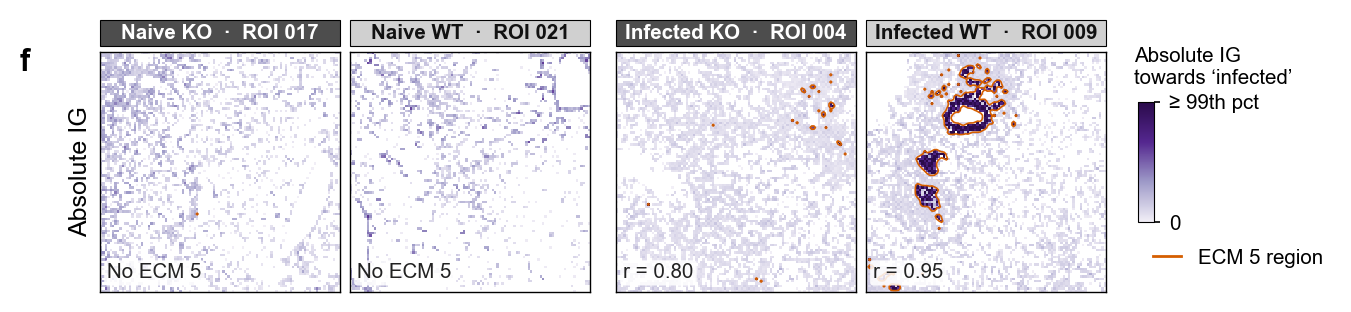

Pearson r between absolute IG and the infection-associated cluster in the ROIs shown (this run: ECM 5; paper: ECM 5; the paper's table lists infected ROIs only)


,group,this run,paper
roi_017,Naive KO,NaN,NaN
roi_021,Naive WT,NaN,NaN
roi_004,Infected KO,0.80,0.86
roi_009,Infected WT,0.95,0.95


In [17]:
canvas = fig3.Canvas(fig3.WF, fig3.HF)
for j, group in enumerate(fig3.GROUPS):
    roi = fig3.REP[group]
    here = patches[patches.roi == roi]
    row, column = fig3.grid_index(here)
    region = np.zeros((GRID, GRID))
    region[row, column] = here.cluster.to_numpy() == INFECTION_CLUSTER
    axis = canvas.A(fig3.colx(j), fig3.rowy2, fig3.MW, fig3.MW)
    axis.imshow(np.ma.masked_invalid(fig3.ig_tile(tables, roi)), cmap=fig3.IMP, vmin=0, vmax=1, interpolation="nearest")
    if 0 < region.sum() < region.size:
        axis.contour(gaussian_filter(region, 0.7), levels=[0.25], colors=[INFECTION_COLOUR], linewidths=0.6)
    r = tables["localisation"].query("roi == @roi and cluster == @INFECTION_CLUSTER").pearson_r
    axis.text(0.03, 0.04, f"r = {r.iloc[0]:.2f}" if len(r) and np.isfinite(r.iloc[0]) else f"No ECM {INFECTION_CLUSTER}",
              transform=axis.transAxes, fontsize=canvas.ST, ha="left", va="bottom", color="#222222",
              bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    fig3._tile(axis)
    if j == 0:
        axis.set_ylabel("Absolute IG", fontsize=canvas.SB, labelpad=3)
    canvas.fband(fig3.colx(j), fig3.colx(j) + fig3.MW, fig3.rowy2 + fig3.MW + 0.03, 0.13, group.split(" ")[1],
                 text=f"{group}  ·  {roi.replace('roi_', 'ROI ')}", fs=canvas.ST)
bar = canvas.fig.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(0, 1), cmap=fig3.IMP),
                          cax=canvas.A(fig3.LX + 0.02, fig3.rowy2 + 0.35, 0.08, 0.6))
bar.set_ticks([0, 1]); bar.set_ticklabels(["0", "≥ 99th pct"])
bar.ax.tick_params(labelsize=canvas.ST, length=2); bar.outline.set_linewidth(0.4)
canvas.fig.text(fig3.LX / fig3.WF, (fig3.rowy2 + 1.02) / fig3.HF, "Absolute IG\ntowards ‘infected’",
                fontsize=canvas.ST, ha="left", va="bottom")
canvas.fig.legend(handles=[Line2D([], [], color=INFECTION_COLOUR, lw=1.0, label=f"ECM {INFECTION_CLUSTER} region")],
                  loc="center left", bbox_to_anchor=(fig3.LX / fig3.WF, (fig3.rowy2 + 0.17) / fig3.HF),
                  frameon=False, fontsize=canvas.ST, handlelength=1.4)
canvas.letter(0.02, fig3.rowy2 + fig3.MW + 0.02, "f")
plt.show()

print(f"Pearson r between absolute IG and the infection-associated cluster in the ROIs shown "
      f"(this run: ECM {INFECTION_CLUSTER}; paper: ECM {PAPER_CLUSTER}; the paper's table lists infected ROIs only)")
localisation = tables["localisation"]
paper_r = paper["h_localisation"].query("cluster == @PAPER_CLUSTER").set_index("roi").pearson_r
pd.DataFrame({"group": list(fig3.REP),
              "this run": localisation[localisation.is_infection_cluster].set_index("roi").pearson_r.reindex(shown),
              "paper": paper_r.reindex(shown)}, index=shown).round(2)

Panel h shows the same correlation for every cluster and every infected ROI (circles: knockout; squares:
wild type; line: median), drawn with the paper's function.

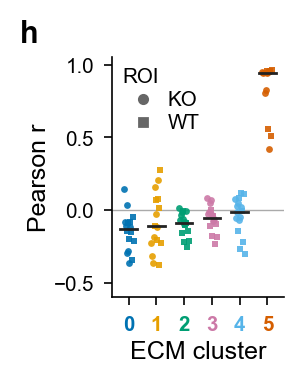

Median Pearson r over the infected ROIs, per cluster (same cluster numbers side by side)


,this run,"ROIs with the cluster, this run",paper,"ROIs with the cluster, paper"
cluster,,,,
ECM 0,-0.13,16,-0.21,16
ECM 1,-0.11,16,-0.02,16
ECM 2,-0.09,16,-0.09,16
ECM 3,-0.05,16,-0.07,16
ECM 4,-0.01,16,-0.03,16
ECM 5,0.94,14,0.95,14


In [18]:
canvas = fig3.Canvas(fig3.WF, fig3.HF)
fig3.panel_h(canvas, tables)
plt.show()

infected_r = localisation[localisation.group.str.startswith("Infected")]
print("Median Pearson r over the infected ROIs, per cluster (same cluster numbers side by side)")
pd.DataFrame({"this run": infected_r.groupby("cluster").pearson_r.median(),
              "ROIs with the cluster, this run": infected_r.groupby("cluster").pearson_r.count(),
              "paper": paper["h_localisation"].groupby("cluster").pearson_r.median(),
              "ROIs with the cluster, paper": paper["h_localisation"].groupby("cluster").pearson_r.count()}
             ).rename(index="ECM {}".format).round(2)

## 16. Connected regions of the infection-associated cluster (Figure 3i)

`mt.tl.component_summary` with `mode="radius"` joins the patches of one cluster that lie within 40 pixels of
each other and returns the connected groups (subgraphs). Subgraphs of at least five patches are kept. For
each one it reports the number of patches and the mean node degree (2 x edges / patches): a high degree
means a compact, densely filled region.

The maps show the two infected ROIs of panels d to f; kept subgraphs are coloured by node degree and smaller
fragments are grey. The plot shows the mean degree of every kept subgraph in the four infected mice. This
panel is also drawn here, because the paper's function writes "ECM 5" and the mouse names into the drawing.

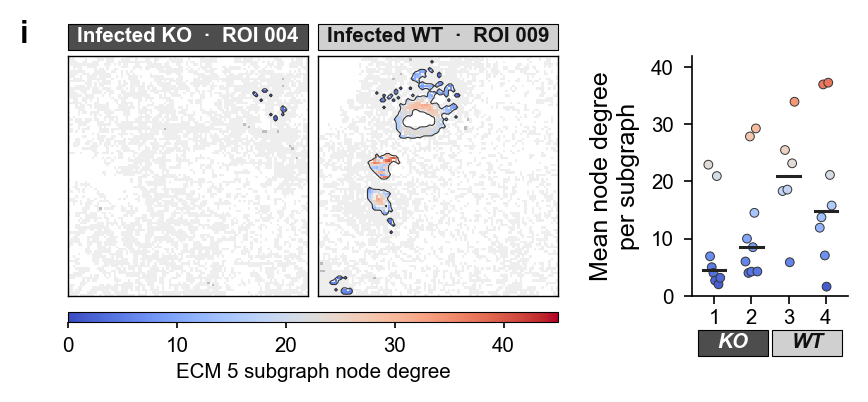

Subgraphs of at least five patches per infected mouse (this run: ECM 5; paper: ECM 5)


,"subgraphs, this run","subgraphs, paper","median patches, this run","median patches, paper","median mean degree, this run","median mean degree, paper"
mouse,,,,,,
mouse_01,8,6.0,10.0,12.5,4.5,5.8
mouse_02,9,10.0,12.0,13.5,8.5,7.7
mouse_03,6,7.0,143.5,61.0,20.9,20.2
mouse_04,8,8.0,61.5,68.5,14.8,16.3


In [19]:
regions = mt.tl.component_summary(
    cohort, target_cluster=int(INFECTION_CLUSTER), mode="radius", radius=40.0, min_nodes=5,
    sample_meta=meta, unit_col="mouse", unit_aggregation="pool_components",
)
kept = regions.components[regions.components.kept.astype(bool)].rename(columns={"sample_id": "roi"})
tables["subgraphs"] = pd.DataFrame({
    "roi": kept.roi.to_numpy(), "mouse": meta.mouse.reindex(kept.roi).to_numpy(), "group": meta.group.reindex(kept.roi).to_numpy(),
    "component": kept.groupby("roi").n_nodes.rank(method="first", ascending=False).to_numpy(int),   # 1 = largest in its ROI
    "n_nodes": kept.n_nodes.to_numpy(), "n_edges": kept.n_edges.to_numpy(),
    "mean_degree": kept.mean_degree.to_numpy(float),
})
tables["subgraph_nodes"] = regions.membership.rename(
    columns={"sample_id": "roi", "kept": "retained", "degree": "node_degree_40px"}
).merge(patches[["roi", "node_id", "x", "y"]], on=["roi", "node_id"], how="left")

canvas = fig3.Canvas(fig3.WF, fig3.HF)
for j, group in ((2, "Infected KO"), (3, "Infected WT")):
    roi = fig3.REP[group]
    image, outline = fig3.degree_map(tables, roi)
    axis = canvas.A(fig3.colx(j), fig3.y3, fig3.MW, fig3.MW)
    axis.imshow(image, interpolation="nearest")
    if 0 < outline.sum() < outline.size:
        axis.contour(gaussian_filter(outline, 0.6), levels=[0.25], colors=["#333333"], linewidths=0.4)
    fig3._tile(axis)
    canvas.fband(fig3.colx(j), fig3.colx(j) + fig3.MW, fig3.y3 + fig3.MW + 0.03, 0.13, group.split(" ")[1],
                 text=f"{group}  ·  {roi.replace('roi_', 'ROI ')}", fs=canvas.ST)
bar = canvas.fig.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(0, fig3.DMAX), cmap=fig3.DEG),
                          cax=canvas.A(fig3.colx(2), fig3.y3 - 0.13, 2 * fig3.MW + fig3.GAP, 0.05), orientation="horizontal")
bar.set_ticks([0, 10, 20, 30, 40]); bar.ax.tick_params(labelsize=canvas.ST, length=2); bar.outline.set_linewidth(0.4)
bar.set_label(f"ECM {INFECTION_CLUSTER} subgraph node degree", fontsize=canvas.ST, labelpad=2.5)

axis = canvas.A(6.12, fig3.y3, 0.78, fig3.H3)
for j, mouse in enumerate(KO_MICE + WT_MICE):
    degree = tables["subgraphs"].loc[tables["subgraphs"].mouse == mouse, "mean_degree"].to_numpy(float)
    if len(degree):
        spread = np.linspace(-0.16, 0.16, len(degree)) if len(degree) > 1 else np.zeros(1)
        axis.scatter(j + spread, degree, s=10, c=fig3.DEG(np.clip(degree / fig3.DMAX, 0, 1)), lw=0.35,
                     edgecolor="#333333", zorder=3)
        axis.plot([j - 0.3, j + 0.3], [np.median(degree)] * 2, color="#222222", lw=1.1, zorder=4)
axis.set_xlim(-0.6, 3.6); axis.set_ylim(0, 42); axis.set_yticks([0, 10, 20, 30, 40])
axis.set_xticks(range(4)); axis.set_xticklabels([str(int(mouse.split("_")[-1])) for mouse in KO_MICE + WT_MICE])
axis.tick_params(axis="x", pad=1.5); axis.set_ylabel("Mean node degree\nper subgraph")
canvas.axbands(axis, [[(-0.45, 1.45, "KO", True), (1.55, 3.45, "WT", True)]], fig3.H3, first=0.17)
canvas.letter(fig3.colx(2) - 0.24, fig3.y3 + fig3.MW + 0.18, "i")
plt.show()

print(f"Subgraphs of at least five patches per infected mouse "
      f"(this run: ECM {INFECTION_CLUSTER}; paper: ECM {PAPER_CLUSTER})")
paper_regions = paper["i_subgraphs"].groupby("mouse")
pd.DataFrame({
    "subgraphs, this run": regions.per_unit.n_components, "subgraphs, paper": paper_regions.size(),
    "median patches, this run": regions.per_unit.median_nodes, "median patches, paper": paper_regions.n_nodes.median(),
    "median mean degree, this run": regions.per_unit.median_mean_degree, "median mean degree, paper": paper_regions.mean_degree.median(),
}).loc[KO_MICE + WT_MICE].round(1)

### Notes

- The CNN starts from random weights, and neither its training nor the classifier's is bit-reproducible on
  a GPU. The six clusters, and every number that follows from them, therefore differ slightly from the paper
  and between machines.
- This is one training seed. The paper's classifier probabilities (Fig. 3g) and integrated gradients
  (Fig. 3f, h) are averages over five seeds; panel g is compared with the paper's seed-0 values as well.
- Background removal gives 107,732 signal patches here and 107,740 in the paper.
- The clusters are numbered by size in each run. If two clusters swap numbers relative to the paper, read
  the "same cluster numbers" tables through the matching table under panel b.
- Not run here: the five-seed ensemble, the permutation test, the tuned classifiers and the supplementary
  controls.
- [Mantpy](https://github.com/moeghaf/Mantpy) · [dataset](https://doi.org/10.5281/zenodo.21538382) ·
  [source data](../source_data/) · [paper figure code](../figures/)